<a href="https://colab.research.google.com/github/Shivaji-Vasanth/Deep-Learning/blob/main/Exp3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Task 1: Generate and Plot Probability Distributions
We will use `scipy.stats` and `matplotlib` to generate random samples for Bernoulli, Binomial, Poisson, Uniform, and Gaussian distributions, then compare them with their analytical PMF/PDF.

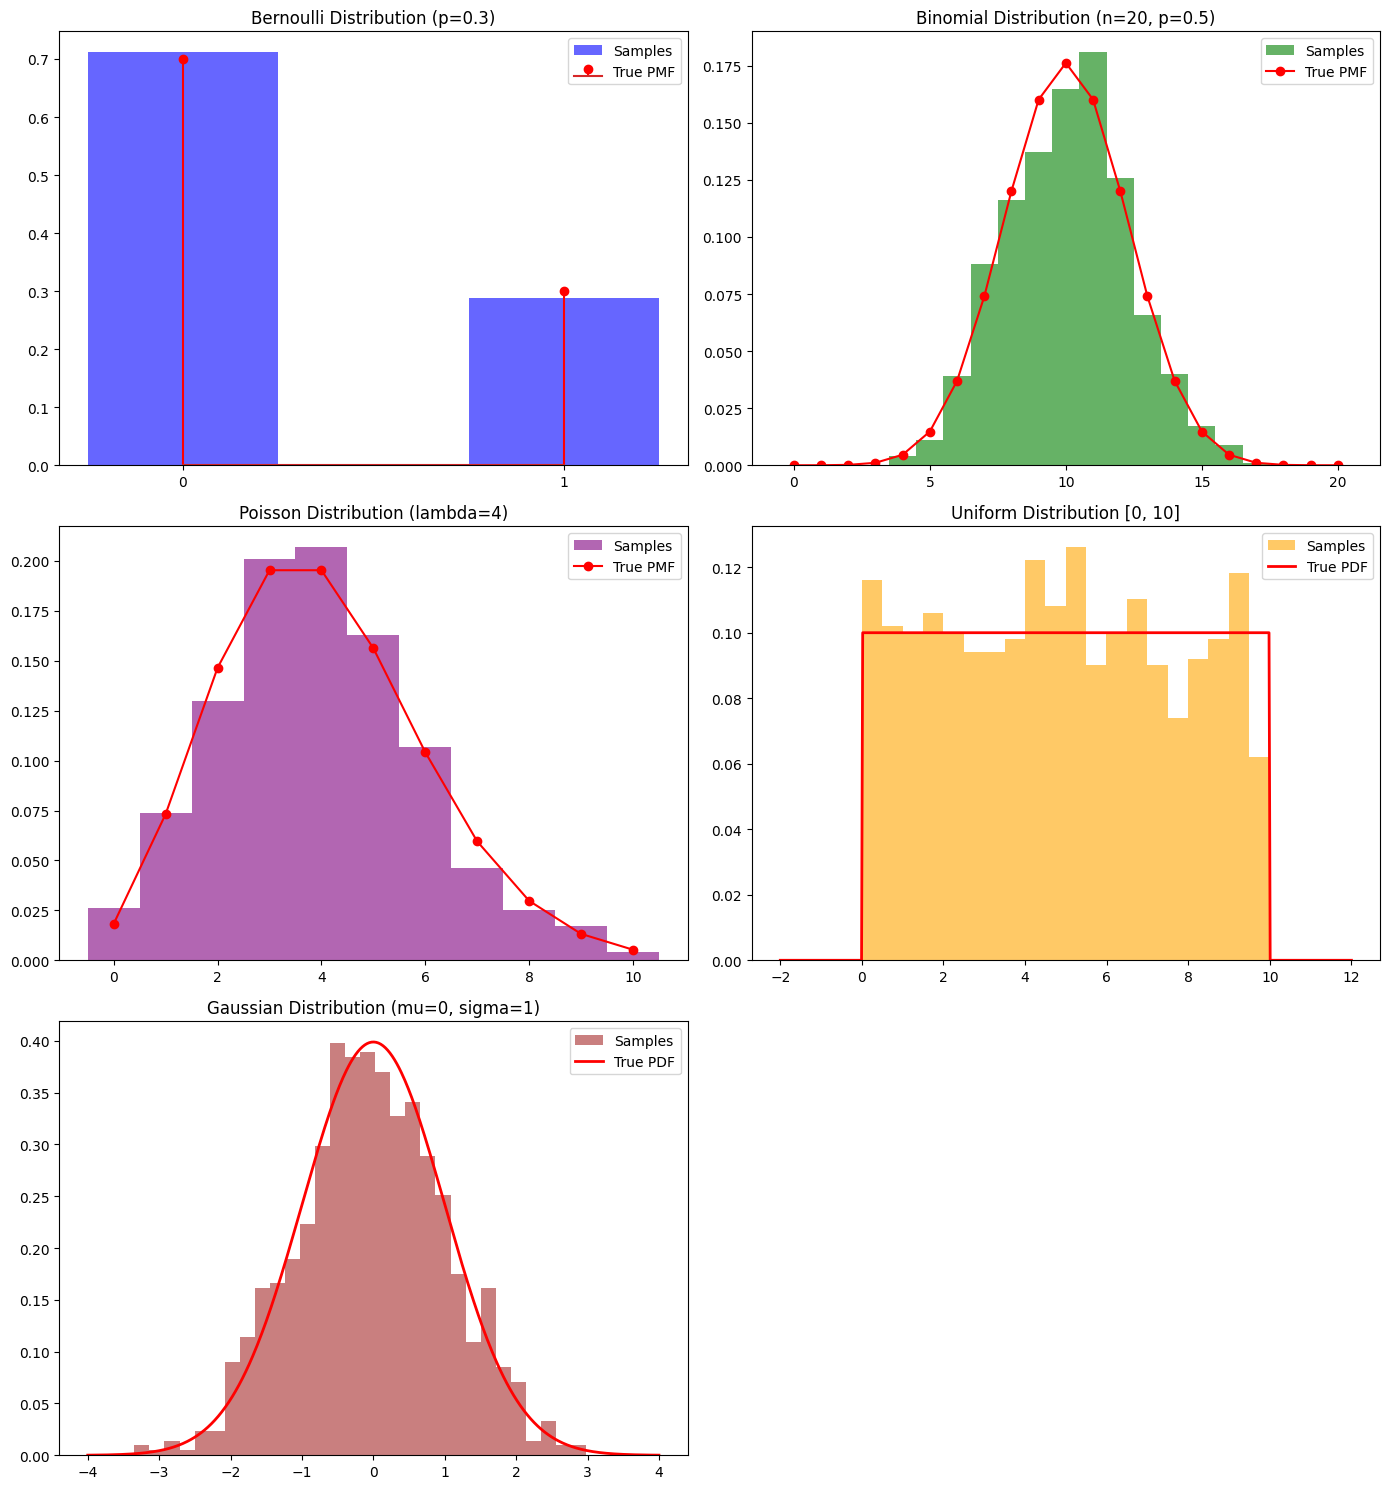

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Set random seed for reproducibility
np.random.seed(42)

# Create subplots for the 5 distributions
fig, axes = plt.subplots(3, 2, figsize=(14, 15))
axes = axes.flatten()

# 1. Bernoulli Distribution (p=0.3)
p_bern = 0.3
bern_samples = stats.bernoulli.rvs(p_bern, size=1000)
x_bern = [0, 1]
axes[0].hist(bern_samples, bins=[-0.5, 0.5, 1.5], density=True, rwidth=0.5, alpha=0.6, color='blue', label='Samples')
axes[0].stem(x_bern, stats.bernoulli.pmf(x_bern, p_bern), linefmt='r-', markerfmt='ro', label='True PMF')
axes[0].set_title("Bernoulli Distribution (p=0.3)")
axes[0].set_xticks([0, 1])
axes[0].legend()

# 2. Binomial Distribution (n=20, p=0.5)
n_bin, p_bin = 20, 0.5
bin_samples = stats.binom.rvs(n=n_bin, p=p_bin, size=1000)
x_bin = np.arange(0, n_bin + 1)
axes[1].hist(bin_samples, bins=np.arange(-0.5, n_bin + 1.5, 1), density=True, alpha=0.6, color='green', label='Samples')
axes[1].plot(x_bin, stats.binom.pmf(x_bin, n_bin, p_bin), 'ro-', label='True PMF')
axes[1].set_title("Binomial Distribution (n=20, p=0.5)")
axes[1].legend()

# 3. Poisson Distribution (mu=4)
mu_poi = 4
poi_samples = stats.poisson.rvs(mu=mu_poi, size=1000)
x_poi = np.arange(0, np.max(poi_samples) + 1)
axes[2].hist(poi_samples, bins=np.arange(-0.5, np.max(poi_samples) + 1.5, 1), density=True, alpha=0.6, color='purple', label='Samples')
axes[2].plot(x_poi, stats.poisson.pmf(x_poi, mu_poi), 'ro-', label='True PMF')
axes[2].set_title("Poisson Distribution (lambda=4)")
axes[2].legend()

# 4. Uniform Distribution (loc=0, scale=10 -> [0, 10])
low, width = 0, 10
uni_samples = stats.uniform.rvs(loc=low, scale=width, size=1000)
x_uni = np.linspace(low - 2, low + width + 2, 500)
axes[3].hist(uni_samples, bins=20, density=True, alpha=0.6, color='orange', label='Samples')
axes[3].plot(x_uni, stats.uniform.pdf(x_uni, loc=low, scale=width), 'r-', lw=2, label='True PDF')
axes[3].set_title("Uniform Distribution [0, 10]")
axes[3].legend()

# 5. Gaussian (Normal) Distribution (mu=0, sigma=1)
mu_norm, sig_norm = 0, 1
norm_samples = stats.norm.rvs(loc=mu_norm, scale=sig_norm, size=1000)
x_norm = np.linspace(-4, 4, 500)
axes[4].hist(norm_samples, bins=30, density=True, alpha=0.6, color='brown', label='Samples')
axes[4].plot(x_norm, stats.norm.pdf(x_norm, loc=mu_norm, scale=sig_norm), 'r-', lw=2, label='True PDF')
axes[4].set_title("Gaussian Distribution (mu=0, sigma=1)")
axes[4].legend()

# Hide the 6th empty subplot
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

### Tasks 2 & 3: Bayes' Theorem Analytical Calculation and Empirical Simulation

In [2]:
# Given probabilities
prevalence = 0.01  # P(Disease) = 1%
sensitivity = 0.95 # P(Positive | Disease) = 95%
specificity = 0.90 # P(Negative | No Disease) = 90%

# Analytical Calculation
# P(Positive) = P(Positive | Disease)*P(Disease) + P(Positive | No Disease)*P(No Disease)
p_pos_given_no_disease = 1 - specificity
p_positive = (sensitivity * prevalence) + (p_pos_given_no_disease * (1 - prevalence))

# P(Disease | Positive) = [P(Positive | Disease) * P(Disease)] / P(Positive)
p_disease_given_positive = (sensitivity * prevalence) / p_positive

print(f"--- Analytical Results ---")
print(f"P(Disease | Positive) = {p_disease_given_positive:.4f} ({p_disease_given_positive * 100:.2f}%)\n")

# Empirical Simulation with 100,000 patients
num_patients = 100000

# True state: 1 if patient has disease, 0 otherwise
has_disease = np.random.binomial(1, prevalence, num_patients)

# Test results based on state
test_positive = np.zeros(num_patients, dtype=int)

# For patients with disease: Sensitivity is the probability of testing positive
positives_with_disease = np.random.binomial(1, sensitivity, size=np.sum(has_disease))
test_positive[has_disease == 1] = positives_with_disease

# For patients without disease: 1 - Specificity is the probability of testing positive
positives_without_disease = np.random.binomial(1, 1 - specificity, size=num_patients - np.sum(has_disease))
test_positive[has_disease == 0] = positives_without_disease

# Verify P(Disease | Positive) empirically
total_positives = np.sum(test_positive)
true_positives = np.sum((test_positive == 1) & (has_disease == 1))

empirical_p = true_positives / total_positives if total_positives > 0 else 0

print(f"--- Empirical Simulation (N = {num_patients:,}) ---")
print(f"Total Testing Positive: {total_positives}")
print(f"True Positives (Have Disease & Positive Test): {true_positives}")
print(f"Empirical P(Disease | Positive) = {empirical_p:.4f} ({empirical_p * 100:.2f}%)")

--- Analytical Results ---
P(Disease | Positive) = 0.0876 (8.76%)

--- Empirical Simulation (N = 100,000) ---
Total Testing Positive: 10867
True Positives (Have Disease & Positive Test): 934
Empirical P(Disease | Positive) = 0.0859 (8.59%)


### Task 4: Posterior Probability vs. Disease Prevalence
Let's plot how $P(\text{Disease} | \text{Positive})$ changes when the prevalence of the disease varies from 0.1% to 20%.

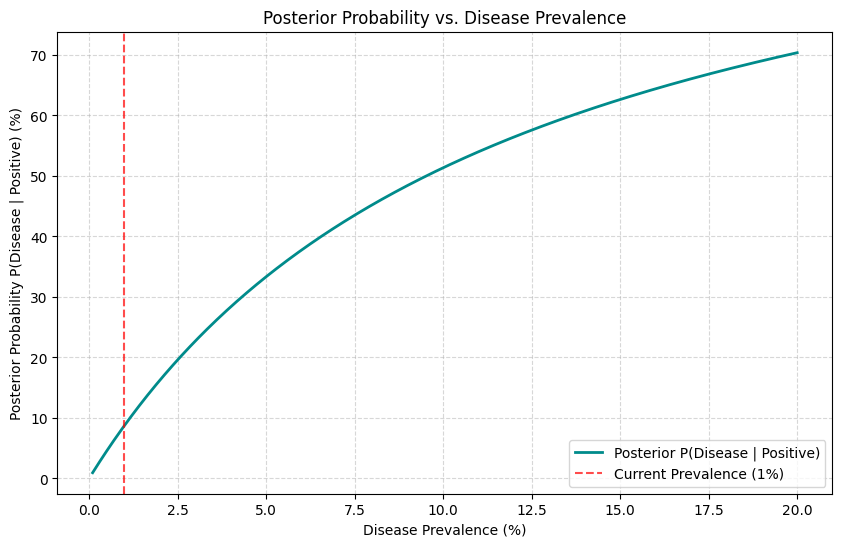

In [3]:
# Range of prevalence from 0.1% (0.001) to 20% (0.20)
prevalence_range = np.linspace(0.001, 0.20, 500)

# Calculate posterior probability for each prevalence value
posterior_probs = []
for prev in prevalence_range:
    p_pos = (sensitivity * prev) + ((1 - specificity) * (1 - prev))
    p_dis_pos = (sensitivity * prev) / p_pos
    posterior_probs.append(p_dis_pos)

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(prevalence_range * 100, np.array(posterior_probs) * 100, label='Posterior P(Disease | Positive)', color='darkcyan', lw=2)
plt.axvline(x=1.0, color='red', linestyle='--', alpha=0.7, label='Current Prevalence (1%)')
plt.title("Posterior Probability vs. Disease Prevalence")
plt.xlabel("Disease Prevalence (%)")
plt.ylabel("Posterior Probability P(Disease | Positive) (%)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()